# Cooling a bowl of soup

In this tutorial, we pour soup at 85 °C into a ceramic bowl at room temperature and ask when it cools to 60 °C, a comfortable temperature to eat. Soup and bowl are two [regions](../overview/modeling/domains.md#regions) of one unstructured mesh with their own coefficients, and heat leaves through [flux boundary conditions](../overview/modeling/boundary-conditions.md) on the tagged edges.

## Setup

We import diff-soup in JAX float64 (double-precision) mode. The mesh is finer on the GPU than on the CPU.

In [1]:
import time

import diff_soup as ds
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from diff_soup.domains.geometry import polygons_to_tagged_mesh
from diff_soup.timestepping import Bisection
from scipy.integrate import solve_ivp, trapezoid

jax.config.update("jax_enable_x64", True)
GPU = jax.default_backend() == "gpu"
H = 0.001 if GPU else 0.003  # target element size, m
print(f"diff-soup {ds.__version__}, JAX {jax.__version__}, {jax.devices()[0]}, H = {H} m")

diff-soup 1.1.0, JAX 0.11.2, cuda:0, H = 0.001 m


## The problem

We model a vertical slice through the middle of the bowl, treating it as a long trough. The temperature $T$ follows the heat equation,

$$
\rho c \, \frac{\partial T}{\partial t} = \nabla \cdot (k \nabla T),
$$

where $\rho c$ is the volumetric heat capacity and $k$ the thermal conductivity. The soup is water, $\rho c = 4.18$ MJ/(m³ K), with an effective conductivity $k = 30$ W/(m K) that stands in for natural convection, the buoyancy-driven flow in the soup. The ceramic has $\rho c = 2.0$ MJ/(m³ K) and $k = 1.5$ W/(m K).

Heat leaves through each boundary as an outward flux $q$ in W/m², into air and a table at $T_a = 20$ °C,

$$
q_\text{surface} = h (T - T_a) + \varepsilon \sigma (T^4 - T_a^4) + q_\text{evap}(T), \qquad
q_\text{wall} = h (T - T_a) + \varepsilon \sigma (T^4 - T_a^4), \qquad
q_\text{table} = h_t (T - T_a),
$$

where the first term is heat transfer to the air or the table, with heat transfer coefficients $h = 10$ W/(m² K) and $h_t = 50$ W/(m² K). The second is thermal radiation, with emissivity $\varepsilon = 0.95$ and the Stefan-Boltzmann constant $\sigma$. Evaporation from the free surface adds $q_\text{evap}$, which follows from $h$ by the Lewis analogy between heat and mass transfer, with the air at 50% relative humidity.

In [2]:
k_soup, k_bowl = 30.0, 1.5  # W/(m K)
rc_soup, rc_bowl = 4.18e6, 2.0e6  # J/(m^3 K)
T_air, h, h_table, emissivity = 20.0, 10.0, 50.0, 0.95


def radiation(T):  # W/m^2, temperatures in degrees C
    return emissivity * 5.67e-8 * ((T + 273.15) ** 4 - (T_air + 273.15) ** 4)


def evaporation(T):  # W/m^2: latent heat x mass transfer coefficient x excess vapour density
    vapour = lambda T, rh: rh * 610.94 * jnp.exp(17.625 * T / (T + 243.04)) * 0.018 / (8.314 * (T + 273.15))
    h_mass = h / (1.2 * 1005.0 * 0.85 ** (2 / 3))
    return 2.4e6 * h_mass * (vapour(T, 1.0) - vapour(T_air, 0.5))

## Build the mesh

The bowl is a half annulus of 70 mm inner and 75 mm outer radius standing on a ring foot. We trace the soup and the bowl as two polygons that share the arc where they touch.

In [3]:
R_in, R_out, y_rim, y_soup = 0.070, 0.075, 0.078, 0.065  # m
foot_in, foot_out = 0.025, 0.035


def arc(R, a, b):  # points on a circle about (0, y_rim), angle 0 straight down
    t = np.linspace(a, b, max(2, int(np.ceil(R * abs(b - a) / H)) + 1))
    return [(R * np.sin(s), y_rim - R * np.cos(s)) for s in t]


a_soup = np.arcsin(np.sqrt(R_in**2 - (y_rim - y_soup) ** 2) / R_in)
a_in, a_out = np.arcsin(foot_in / R_out), np.arcsin(foot_out / R_out)
foot = lambda s: [(s * foot_out, y_rim - R_out * np.cos(a_out)), (s * foot_out, 0.0),
                  (s * foot_in, 0.0), (s * foot_in, y_rim - R_out * np.cos(a_in))]
soup = arc(R_in, -a_soup, a_soup)  # the closing edge, right to left, is the free surface
bowl = (soup + arc(R_in, a_soup, np.pi / 2)[1:] + arc(R_out, np.pi / 2, a_out)[:-1] + foot(1)
        + arc(R_out, a_in, -a_in)[1:-1] + foot(-1)[::-1] + arc(R_out, -a_out, -np.pi / 2)[1:]
        + arc(R_in, -np.pi / 2, -a_soup)[:-1])

Next, we mesh both polygons into one conforming triangular mesh with `polygons_to_tagged_mesh`, which tags each triangle with the name of its polygon and the shared arc with `"bowl|soup"`. The outer edge of the bowl meets the air and the table under different boundary laws, so the edges resting on the table need a tag of their own. With `segment_tags` we tag each polygon edge, and `segment_names` names the tags `"surface"`, `"wall"` and `"table"`.

In [4]:
on_table = [p[1] == q[1] == 0.0 for p, q in zip(bowl, bowl[1:] + bowl[:1])]  # the two foot edges at y = 0
mesh = polygons_to_tagged_mesh(
    {"soup": soup, "bowl": bowl},
    mesh_size=H,
    segment_tags={"soup": [1] * len(soup), "bowl": [3 if edge else 2 for edge in on_table]},
    segment_names={1: "surface", 2: "wall", 3: "table"},
)
print(mesh.tag_names, mesh.cell_tag_names)

{1: 'surface', 2: 'wall', 3: 'table', 4: 'bowl|soup'} {'soup': 1, 'bowl': 2}


We plot the mesh with each boundary edge coloured by its tag.

8737 nodes, 17021 triangles, 13746 of them soup


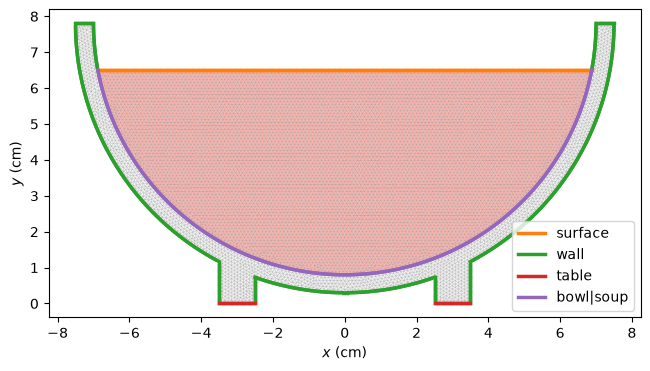

In [5]:
P, cells, edges = np.asarray(mesh.points), np.asarray(mesh.cells), np.asarray(mesh.boundary_edges)
print(f"{mesh.num_nodes} nodes, {len(cells)} triangles, {int(np.sum(mesh.cell_indicator('soup')))} of them soup")

fig, ax = plt.subplots(figsize=(8, 4))
ax.tripcolor(P[:, 0] * 100, P[:, 1] * 100, cells, facecolors=np.asarray(mesh.cell_indicator("soup")),
             cmap="Pastel1_r", edgecolors="0.5", linewidth=0.1)
for tag, name in mesh.tag_names.items():
    for i, e in enumerate(edges[np.asarray(mesh.boundary_tags) == tag]):
        ax.plot(P[e, 0] * 100, P[e, 1] * 100, color=f"C{tag}", lw=2.5, label=None if i else name)
ax.set(xlabel="$x$ (cm)", ylabel="$y$ (cm)", aspect="equal")
ax.legend(loc="lower right")
plt.show()

## Build the model

We write each coefficient that differs between soup and bowl as a weighted sum of the two region indicators, so that it takes one value per triangle. `mesh.cell_indicator(name)` gives each indicator, which is one on the triangles of a [region](../overview/modeling/domains.md#regions) and zero elsewhere.

In [6]:
def per_region(soup_value, bowl_value):
    return soup_value * mesh.cell_indicator("soup") + bowl_value * mesh.cell_indicator("bowl")


k_cell, rc_cell = per_region(k_soup, k_bowl), per_region(rc_soup, rc_bowl)

Since $\rho c$ varies in space, we write the equation in implicit form, as the residual $\rho c \, \partial T / \partial t - \nabla \cdot (k \nabla T)$, so that $\rho c$ enters the mass matrix. In it, `q.dt("T")` is the time derivative of $T$, and both `div_flux` and the factor on `q.dt` take one value per triangle.

In [7]:
spec = ds.problem("soup")
spec.domain("bowl", mesh)
spec.field("T", mass="differential", scale=1.0)


@spec.equation(writes="T", reads=("T",))
def conduction(q):
    return rc_cell * q.dt("T") - q.ops.div_flux(k_cell, q.T)

Each boundary condition selects its edges by tag, and since `spec.bc.flux` takes the flux into the domain, each `fn` returns $-q$. A node on the shared arc belongs to both regions, so it starts at the capacity-weighted average of the two temperatures, using the per-node heat capacity from `ds.Operators(mesh).integrate`.

In [8]:
spec.bc.flux("T", tag="surface", fn=lambda q, t: -(h * (q.T - T_air) + radiation(q.T) + evaporation(q.T)))
spec.bc.flux("T", tag="wall", fn=lambda q, t: -(h * (q.T - T_air) + radiation(q.T)))
spec.bc.flux("T", tag="table", fn=lambda q, t: -h_table * (q.T - T_air))
problem = spec.build()
ops = ds.Operators(mesh)
node_capacity = np.asarray(ops.integrate(rc_cell))  # J/(m K)


def initial_state(T_soup, T_bowl):
    T0 = ops.integrate(per_region(rc_soup * T_soup, rc_bowl * T_bowl)) / node_capacity
    return spec.assemble_state({"T": T0})

## Solve

We stop the solve with a termination [event](../overview/simulation/events.md) when the mean soup temperature falls through 60 °C, and `Bisection` locates the crossing between two steps. The first call jit compiles the solve, so we time a second call as well.

In [9]:
soup_weights = ops.integrate(mesh.cell_indicator("soup"))
soup_mean = lambda u: jnp.dot(soup_weights, u) / soup_weights.sum()
ready = ds.Event(lambda t, u, args, control=None: soup_mean(u) - 60.0, root_finder=Bisection(), direction="down")
ts = np.arange(0.0, 1801.0, 2.0)  # up to 30 min, every 2 s
solve = lambda y0: ds.pdesolve(problem, ds.JIDA(), (0.0, 1800.0), y0, saveat=ds.SaveAt(ts=ts), event=ready)

y0 = initial_state(85.0, T_air)
for label in ("compile and run", "run"):
    start = time.perf_counter()
    sol = jax.block_until_ready(solve(y0))
    print(f"{label}: {time.perf_counter() - start:.2f} s")
t_ready = float(sol.terminal.t)
print(f"ok: {bool(sol.ok)}, {int(sol.stats.accepts)} steps, ready to eat after {t_ready / 60:.1f} min")

compile and run: 1.94 s


run: 0.24 s
ok: True, 221 steps, ready to eat after 10.4 min


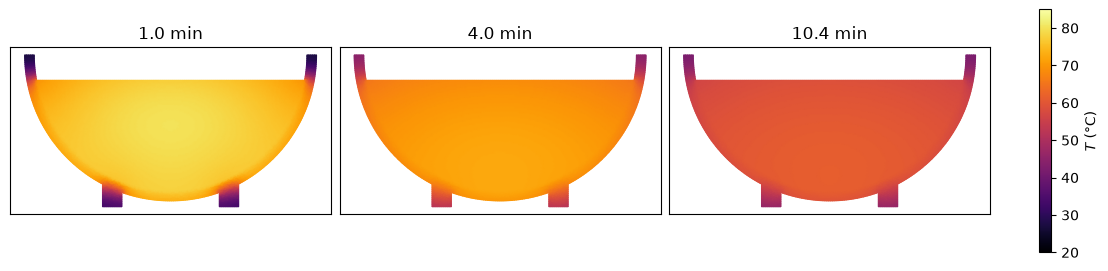

In [10]:
valid = np.asarray(sol.valid_mask)
t_saved, ys = np.asarray(sol.ts)[valid], np.asarray(sol.ys)[valid]
fig, axs = plt.subplots(1, 3, figsize=(11, 2.6), constrained_layout=True)
for ax, t_show in zip(axs, [60.0, 240.0, t_ready]):
    i = int(np.argmin(np.abs(t_saved - t_show)))
    im = ax.tripcolor(P[:, 0] * 100, P[:, 1] * 100, cells, ys[i], shading="gouraud",
                      cmap="inferno", vmin=T_air, vmax=85.0)
    ax.set(aspect="equal", title=f"{t_saved[i] / 60:.1f} min", xticks=[], yticks=[])
fig.colorbar(im, ax=axs, label="$T$ (°C)")
plt.show()

After one minute the bowl has drawn heat out of the soup next to it, while its rim and foot are still cold. When the soup reaches 60 °C after 10.4 minutes, soup and bowl are close to one temperature.

## Check

By conservation of energy, the heat stored in the section falls by exactly the heat that leaves through the three tagged boundaries. We integrate the boundary fluxes over each tag with `ds.surface_measure` and over time with the trapezoidal rule.

In [11]:
loss = {
    "surface": lambda T: h * (T - T_air) + radiation(T) + evaporation(T),
    "wall": lambda T: h * (T - T_air) + radiation(T),
    "table": lambda T: h_table * (T - T_air),
}
measure = {tag: ds.surface_measure(mesh, on=tag) for tag in loss}
rate = {tag: np.array([measure[tag].integrate(f(u)) for u in ys]) for tag, f in loss.items()}
lost = {tag: trapezoid(r, t_saved) for tag, r in rate.items()}
stored = node_capacity @ ys[0] - node_capacity @ ys[-1]
print(f"stored heat fell by {stored:.1f} J/m, boundaries lost {sum(lost.values()):.1f} J/m")
print(f"relative difference {stored / sum(lost.values()) - 1:.1e}")
coarse = sum(trapezoid(np.append(r[:-1:5], r[-1]), np.append(t_saved[:-1:5], t_saved[-1])) for r in rate.values())
print(f"relative difference with every fifth sample {stored / coarse - 1:.1e}")

stored heat fell by 518612.7 J/m, boundaries lost 518644.9 J/m
relative difference -6.2e-05
relative difference with every fifth sample -6.7e-04


The stored heat and the boundary losses agree to a relative difference of $6 \times 10^{-5}$. The gap grows $10\times$ when we keep only every fifth sample, so it comes from the quadrature in time over the saved samples. As a second check, we compare with a lumped model, which treats soup and bowl as one body at a single temperature with the same boundary laws.

In [12]:
length = {tag: float(m.total) for tag, m in measure.items()}
capacity = node_capacity.sum()
T_mixed = node_capacity @ ys[0] / capacity
lumped_rhs = lambda t, T: [-sum(length[tag] * float(f(T[0])) for tag, f in loss.items()) / capacity]
crossing = lambda t, T: T[0] - 60.0
crossing.terminal = True
lumped_sol = solve_ivp(lumped_rhs, (0.0, 1800.0), [T_mixed], events=crossing, max_step=10.0)
print(f"lumped model: starts at {T_mixed:.1f} C, ready after {lumped_sol.t_events[0][0] / 60:.1f} min")

lumped model: starts at 78.7 C, ready after 9.0 min


The lumped model starts from the mixed temperature of 78.7 °C and keeps the outer wall as hot as the soup, so it reaches 60 °C sooner, after 9.0 minutes. On the mesh, the ceramic between the soup and the air stays cooler and slows the loss.

## Tags and regions

Since each tag carries its own boundary law, the heat budget splits by tag. Each region can also start at its own temperature. A bowl warmed to 85 °C before serving changes only the initial state, so the second solve is not jit compiled again.

surface   74.5% of the heat lost
wall      22.2% of the heat lost
table      3.2% of the heat lost


warmed bowl: ready after 12.5 min (0.18 s)


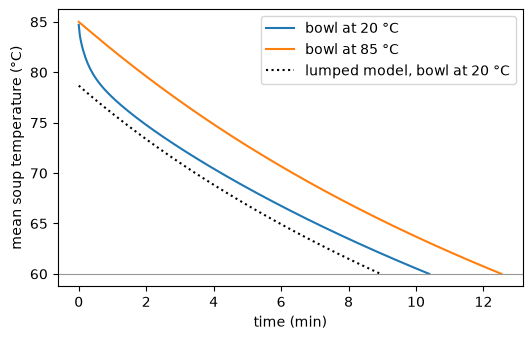

In [13]:
for tag, value in lost.items():
    print(f"{tag:8s} {value / sum(lost.values()):6.1%} of the heat lost")
start = time.perf_counter()
sol_warm = jax.block_until_ready(solve(initial_state(85.0, 85.0)))
t_warm = float(sol_warm.terminal.t)
print(f"warmed bowl: ready after {t_warm / 60:.1f} min ({time.perf_counter() - start:.2f} s)")

fig, ax = plt.subplots(figsize=(6, 3.6))
for s, label in [(sol, "bowl at 20 °C"), (sol_warm, "bowl at 85 °C")]:
    keep = np.asarray(s.valid_mask)
    ax.plot(np.asarray(s.ts)[keep] / 60, [soup_mean(u) for u in np.asarray(s.ys)[keep]], label=label)
ax.plot(lumped_sol.t / 60, lumped_sol.y[0], "k:", label="lumped model, bowl at 20 °C")
ax.axhline(60.0, color="0.6", lw=0.8)
ax.set(xlabel="time (min)", ylabel="mean soup temperature (°C)")
ax.legend()
plt.show()

About three quarters of the heat leaves through the free surface, which is where a lid would act. The cold bowl takes the first few degrees out of the soup within a minute, and warming it first keeps the soup above 60 °C for about two minutes longer.